# Занятие 1. Преобразования координат и системы координат Денавита — Хартенберга — демонстрации

Учебник: Зенкевич С. Л., Ющенко А. С., глава 1. Библиотека `kinlib.py`.

| № | Демонстрация | Слайды | Книга |
|---|---|---|---|
| 1 | Матрица поворота по столбцам, ортогональность | 9–10 | § 1.2 |
| 2 | Порядок поворотов: подвижные и неподвижные оси | 11 | п. 1.2.2 |
| 3 | Углы Эйлера и особая ориентация | 12 | п. 1.2.3 |
| 4 | Однородная матрица, её обращение, пример 1.2 | 18–20 | § 1.3 |
| 5 | Матрица звена по параметрам Денавита — Хартенберга | 24 | (2.8) |
| 6 | Системы координат звеньев шестизвенного робота | 22–23 | § 1.5 |
| 7 | Две таблицы параметров — один робот | 26–27 | § 1.5 |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('.'))
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation
from kinlib import *
np.set_printoptions(precision=4, suppress=True)
%matplotlib inline

def Rx(a): return Rotation.from_euler('x', a).as_matrix()
def Ry(a): return Rotation.from_euler('y', a).as_matrix()
def Rz(a): return Rotation.from_euler('z', a).as_matrix()

def draw_frame(ax, R, p=(0, 0, 0), L=1.0, labels='uvw', alpha=1.0, lw=2.5):
    p = np.asarray(p, dtype=float)
    for k, col in enumerate(('red', 'green', 'blue')):
        e = p + L * R[:, k]
        ax.plot([p[0], e[0]], [p[1], e[1]], [p[2], e[2]], color=col, lw=lw, alpha=alpha)
        ax.text(e[0], e[1], e[2], labels[k], color=col, fontsize=11)

def setup3d(ax, lim=1.2, title=''):
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_zlim(-lim, lim)
    ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z'); ax.set_title(title, fontsize=10)
    draw_frame(ax, np.eye(3), L=0.6, labels='xyz', alpha=0.35, lw=1.5)

## 1. Матрица поворота по столбцам

Столбцы $R$ — орты подвижной системы $u, v, w$, записанные в неподвижной. Проверяем $R^{\mathrm T}R = E$, $\det R = 1$ и пересчёт координат точки $\mathbf p_{xyz} = R\,\mathbf p_{uvw}$.

R =
 [[ 0.766  -0.5826  0.2717]
 [ 0.6428  0.6943 -0.3237]
 [ 0.      0.4226  0.9063]]
орт u в неподвижных осях = [0.766  0.6428 0.    ] 
R^T R =
 [[ 1. -0.  0.]
 [-0.  1. -0.]
 [ 0. -0.  1.]] 
det R = 1.000000
p_uvw = [0.8 0.3 0.5]  ->  p_xyz = R p_uvw = [0.5739 0.5606 0.5799]  -> обратно R^T p_xyz = [0.8 0.3 0.5]


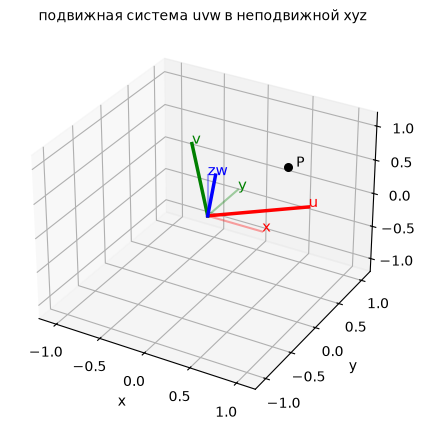

In [2]:
R = Rz(np.radians(40)) @ Rx(np.radians(25))
print('R =\n', R)
print('орт u в неподвижных осях =', R[:, 0], '\nR^T R =\n', (R.T @ R).round(10), '\ndet R = %.6f' % np.linalg.det(R))
p_uvw = np.array([0.8, 0.3, 0.5])
print('p_uvw =', p_uvw, ' ->  p_xyz = R p_uvw =', R @ p_uvw, ' -> обратно R^T p_xyz =', R.T @ (R @ p_uvw))
fig = plt.figure(figsize=(5.5, 5)); ax = fig.add_subplot(111, projection='3d'); setup3d(ax, title='подвижная система uvw в неподвижной xyz')
draw_frame(ax, R); P = R @ p_uvw; ax.scatter(*P, color='k', s=30); ax.text(*P, '  P')
plt.show()

## 2. Порядок поворотов

Поворот вокруг оси **подвижной** системы дописывается **справа**, вокруг оси **неподвижной** — **слева**. Два поворота на $90^\circ$ в разном порядке дают разные ориентации (пример 1.1 конспекта).

Rz Rx =
 [[ 0. -0.  1.]
 [ 1.  0. -0.]
 [ 0.  1.  0.]] 
Rx Rz =
 [[ 0. -1.  0.]
 [ 0.  0. -1.]
 [ 1.  0.  0.]] 
коммутируют: False


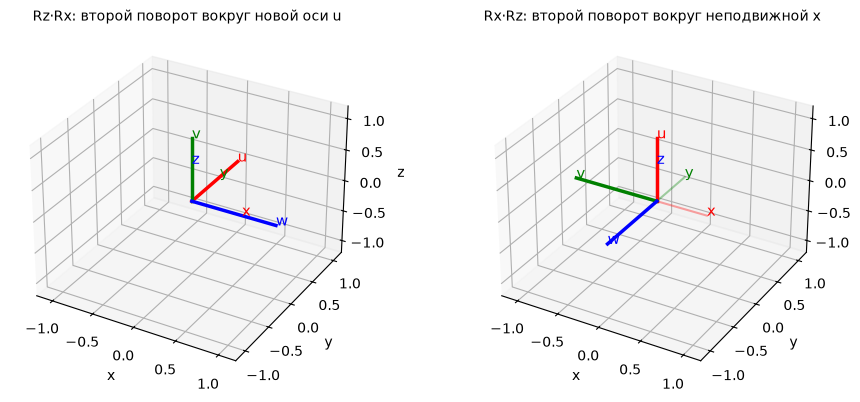

In [3]:
A = Rz(np.pi/2) @ Rx(np.pi/2)      # z, затем новая ось x (подвижные оси)
B = Rx(np.pi/2) @ Rz(np.pi/2)      # z, затем НЕПОДВИЖНАЯ ось x
print('Rz Rx =\n', A.round(3), '\nRx Rz =\n', B.round(3), '\nкоммутируют:', np.allclose(A, B))
fig = plt.figure(figsize=(11, 4.6))
for k, (M, t) in enumerate(((A, 'Rz·Rx: второй поворот вокруг новой оси u'), (B, 'Rx·Rz: второй поворот вокруг неподвижной x'))):
    ax = fig.add_subplot(1, 2, k + 1, projection='3d'); setup3d(ax, title=t); draw_frame(ax, M)
plt.show()

## 3. Углы Эйлера и особая ориентация

$R(\varphi,\theta,\psi) = R_{z,\varphi}R_{y,\theta}R_{z,\psi}$. При $\theta = 0$ первый и третий повороты происходят вокруг одной оси: различима только сумма $\varphi + \psi$.

In [4]:
euler = lambda phi, th, psi: Rz(phi) @ Ry(th) @ Rz(psi)
R1 = euler(np.radians(30), 0.0, np.radians(50)); R2 = euler(np.radians(70), 0.0, np.radians(10))
print('theta = 0: (30, 0, 50) и (70, 0, 10) дают одну матрицу:', np.allclose(R1, R2))
R3 = euler(np.radians(30), np.radians(40), np.radians(50)); R4 = euler(np.radians(70), np.radians(40), np.radians(10))
print('theta = 40: те же phi, psi дают разные матрицы:', not np.allclose(R3, R4))
# восстановление углов по матрице (лекция 2, пример 2.9)
x, y, z = R3[:, 0], R3[:, 1], R3[:, 2]
phi = np.arctan2(z[1], z[0]); th = np.arctan2(z[0]*np.cos(phi) + z[1]*np.sin(phi), z[2])
psi = np.arctan2(-x[0]*np.sin(phi) + x[1]*np.cos(phi), -y[0]*np.sin(phi) + y[1]*np.cos(phi))
print('углы из матрицы: phi, theta, psi =', np.degrees([phi, th, psi]).round(3))

theta = 0: (30, 0, 50) и (70, 0, 10) дают одну матрицу: True
theta = 40: те же phi, psi дают разные матрицы: True
углы из матрицы: phi, theta, psi = [30. 40. 50.]


## 4. Однородная матрица и её обращение. Пример 1.2

$T^{-1}$ выписывается без численного обращения: блок поворота транспонируется, перенос равен $-R^{\mathrm T}\mathbf p$.

T =
 [[ 1.  0.  0.  0.]
 [ 0.  0. -1. 10.]
 [ 0.  1.  0.  5.]
 [ 0.  0.  0.  1.]] 
точка M в системе O1:  [ 0. 20.  5.  1.]
T^-1 по формуле =
 [[ 1.  0.  0. -0.]
 [ 0.  0.  1. -5.]
 [ 0. -1.  0. 10.]
 [ 0.  0.  0.  1.]] 
совпадает с numpy.linalg.inv: True


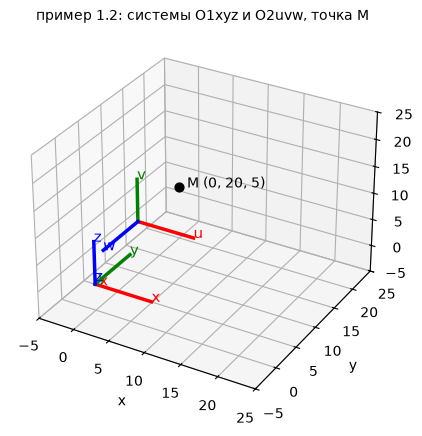

In [5]:
T = Frame(np.array([[1, 0, 0, 0], [0, 0, -1, 10], [0, 1, 0, 5], [0, 0, 0, 1.0]]))
M = np.array([0, 0, -10, 1.0])
print('T =\n', T, '\nточка M в системе O1: ', T.t_4_4 @ M)
print('T^-1 по формуле =\n', T.inv, '\nсовпадает с numpy.linalg.inv:', np.allclose(T.inv.t_4_4, np.linalg.inv(T.t_4_4)))
fig = plt.figure(figsize=(5.5, 5)); ax = fig.add_subplot(111, projection='3d'); setup3d(ax, lim=22, title='пример 1.2: системы O1xyz и O2uvw, точка M')
draw_frame(ax, np.eye(3), L=8, labels='xyz'); draw_frame(ax, T.r_3_3, p=T.t_3_1.ravel(), L=8)
Pm = (T.t_4_4 @ M)[:3]; ax.scatter(*Pm, color='k', s=40); ax.text(*Pm, '  M (0, 20, 5)'); ax.set_xlim(-5, 25); ax.set_ylim(-5, 25); ax.set_zlim(-5, 25)
plt.show()

## 5. Матрица звена по параметрам Денавита — Хартенберга

Четыре элементарных движения в подвижных осях: $A_i = \mathrm{Rot}(z, q_i)\,\mathrm{Trans}(z, d_i)\,\mathrm{Trans}(x, a_i)\,\mathrm{Rot}(x, \alpha_i)$ — совпадает с формулой (2.8).

In [6]:
def hom(R=np.eye(3), p=(0, 0, 0)):
    return Frame.from_r_3_3(R, np.reshape(p, (3, 1)))
d, a, alpha, q = 0.3, 0.5, np.radians(-90), np.radians(35)
A_steps = hom(Rz(q)) * hom(p=(0, 0, d)) * hom(p=(a, 0, 0)) * hom(Rx(alpha))
A_formula = Frame.from_dh((d, a, alpha, q))
print('произведение четырёх движений =\n', A_steps, '\nформула (2.8) =\n', A_formula, '\nсовпадают:', np.allclose(A_steps.t_4_4, A_formula.t_4_4))

произведение четырёх движений =
 [[ 0.819 -0.    -0.574  0.41 ]
 [ 0.574  0.     0.819  0.287]
 [ 0.    -1.     0.     0.3  ]
 [ 0.     0.     0.     1.   ]] 
формула (2.8) =
 [[ 0.819 -0.    -0.574  0.41 ]
 [ 0.574  0.     0.819  0.287]
 [ 0.    -1.     0.     0.3  ]
 [ 0.     0.     0.     1.   ]] 
совпадают: True


## 6. Системы координат звеньев шестизвенного робота

`axis_frames` возвращает матрицы $T_1 \dots T_N$; рисуем оси $x_i$ (красная) и $z_i$ (синяя) каждого звена. Ось $z_{i-1}$ — ось $i$-го сочленения.

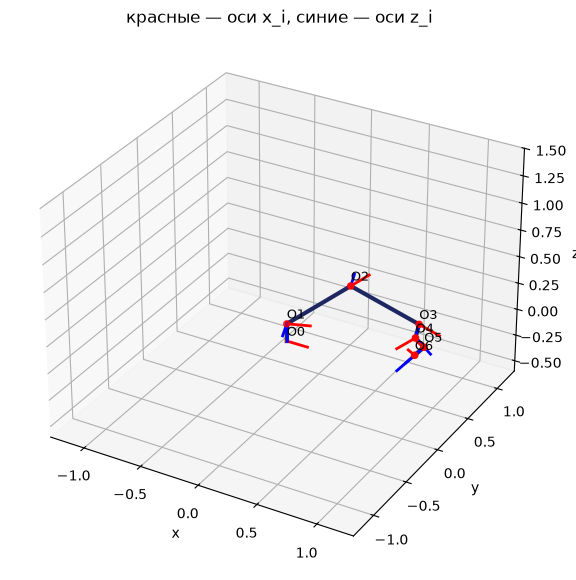

таблица ДХ | d | a | alpha | theta0 |
 [[ 0.163   0.      1.5708  0.    ]
 [ 0.      0.632   3.1416  1.5708]
 [ 0.      0.6005  3.1416  0.    ]
 [ 0.2013  0.     -1.5708 -1.5708]
 [ 0.1025  0.      1.5708  0.    ]
 [ 0.094   0.      0.      0.    ]]


In [7]:
robot = make_ur()
robot.forward(np.radians([20, -50, 70, -20, 60, 0]))
fig = plt.figure(figsize=(7, 7)); ax = fig.add_subplot(111, projection='3d')
robot.draw(ax=ax, cylinders=False, frame_len=0.0)
frames = [Frame.i_4_4()] + robot.axis_frames
for i, f in enumerate(frames):
    p = f.t_3_1.ravel()
    for k, col in ((0, 'red'), (2, 'blue')):
        e = p + 0.18 * f.r_3_3[:, k]; ax.plot([p[0], e[0]], [p[1], e[1]], [p[2], e[2]], color=col, lw=2)
    ax.text(p[0], p[1], p[2] + 0.05, 'O%d' % i, fontsize=9)
ax.set_title('красные — оси x_i, синие — оси z_i'); plt.show()
print('таблица ДХ | d | a | alpha | theta0 |\n', UR_DH)

## 7. Две таблицы параметров — один робот

Направление оси $z_1$ плоского двухзвенника можно выбрать «на нас» или «от нас». Таблицы получаются разные (меняются знаки углов и $\alpha$), но физически та же конфигурация даёт то же положение схвата.

In [8]:
a1, a2 = 1.0, 0.7
tabA = np.array([[0, a1, 0, 0], [0, a2, 0, 0]])                    # все оси z «на нас»
tabB = np.array([[0, a1, np.pi, 0], [0, a2, np.pi, 0]])             # z1 «от нас», z2 снова «на нас»
rA, rB = RobotSerial(tabA), RobotSerial(tabB)
q1, q2 = np.radians(30), np.radians(45)
pA = rA.forward([q1, q2]).t_3_1.ravel()
pB = rB.forward([q1, -q2]).t_3_1.ravel()                            # во второй таблице угол второго сочленения отсчитывается в обратную сторону
print('таблица A, q = (30, 45):   схват', pA.round(4)); print('таблица B, q = (30, -45):  схват', pB.round(4)); print('совпадают:', np.allclose(pA, pB))

таблица A, q = (30, 45):   схват [1.0472 1.1761 0.    ]
таблица B, q = (30, -45):  схват [ 1.0472  1.1761 -0.    ]
совпадают: True
